# Part 1A: Data Exploration

**Candidate Name:** Matteo Antony Mistretta

**Date:** 2026-10-17

**Environment:** Python 3.14, PyTorch 2.14, scikit-learn 1.9, pandas, umap-learn (exact versions in `requirements.txt`). Random seed fixed to 42 throughout.

**Downloaded on first run:** the PubMedBERT tokenizer (Part 1A, ~236 KB) is fetched from Hugging Face the first time the notebook runs, then cached in `~/.cache/huggingface`. It is pinned to a fixed revision so every run uses exactly the same vocabulary. Internet access is needed only for that first run.

## Part 1A: Data Exploration

*Analyze dataset characteristics and category distribution*

**Goal of this section.** Before building any model, I need to understand the data I will be classifying: what it looks like, how it is distributed, and what could go wrong. Every finding here should lead to a concrete decision later (how to split the data, which metric to use, what errors to expect).

**What the data is.** Each row of `data/endpoints_data.csv` is a *triplet* used to train the embedding model, plus some metadata:

| Column | Meaning | Role in this test |
|---|---|---|
| `anchor` | A clinical endpoint text, e.g. *"Cl/F"* | **The input I will classify** |
| `positive` | A text with similar meaning, e.g. *"Total body clearance"* | Context: part of the embedding model's training data |
| `negative` | A text with different meaning, e.g. *"Maximum concentration"* | Context: part of the embedding model's training data |
| `case` | The category of the anchor (9 possible values) | **The label I will predict** |
| `is_coa_tool`, `is_synthetic`, `is_root_pair_similar` | True/False flags | Investigated below |

In machine-learning terms, the category in `case` is the **label**: the correct answer attached to each example, which the model learns from and is scored against. In this notebook "label" and "category" mean the same thing.

**Plan:** (1) data quality, (2) how many examples per category, (3-4) what the texts look like, (5) what the metadata flags mean.

### Domain background: what is in this dataset?

I am not a clinician, so before exploring the data I looked up what these texts are.

**Each anchor is the name of a clinical trial endpoint**: something a trial *measures* to decide whether a treatment works or is safe. Before a trial starts, it declares its endpoints (e.g. on registries like ClinicalTrials.gov). The dataset contains these **names only, not results**: *"28-day mortality"* says that a trial measured mortality, not what the mortality was. The trials are mostly about drugs, but also surgery (*"Postoperative bleeding (mL)"*), devices, vaccines and behavioural studies (*"smoking habit"*). Several real anchors are truncated fragments (*"All-cause death or"*), which suggests they were extracted automatically from such registrations.

**Why classify them:** every trial words its endpoints differently (*"CV mortality"*, *"death from cardiovascular causes"*, *"Cardiovascular mortality"* are all in the data). Mapping each name to a standard category makes trials searchable and comparable, e.g. *"all trials that measured mortality"*.

**The 9 categories:**
- **Pharmacokinetic (PK)**: what the body does *to the drug*: absorption, concentration in blood, elimination.
- **Immunogenicity**: whether the immune system reacts to the treatment (antibodies; the goal for vaccines, usually unwanted for drugs).
- **Adverse Event**: safety, i.e. unwanted medical events during the trial (side effects, toxicity).
- **Complications**: problems caused by the disease or a procedure (e.g. postoperative infection); close to Adverse Event.
- **Mortality**: death, all-cause or from a specific cause.
- **COA Tool**: *Clinical Outcome Assessment* instruments: named questionnaires and scales (e.g. quality-of-life questionnaires, pain scales).
- **Cost**: health economics, i.e. money and resources used or saved.
- **Demographic**: characteristics of the participants (age, sex, education, smoking status).
- **General Case**: everything else, mostly lab values and clinical measurements (*"serum protein levels"*, *"oxygen saturation"*).

**Worked example: the first row.** Anchor *"Cl/F"* (lowercase *L*, for **clearance**) is the volume of blood plasma the body clears of the drug per hour, divided by *F*, the fraction of an oral dose that reaches the blood. Its positive, *"Total body clearance"*, is a near-synonym. Its negative, *"Maximum concentration"*, is a different measurement (how high the drug level peaks) **but in the same category, Pharmacokinetic**. So the triplets teach the embedding model **"same meaning or not"**, *not* **"same category or not"**. This distinction will matter when judging how well the embeddings separate the categories.

### Setup

**What:** import the libraries used in this section and set a few options.
- `pandas` loads the CSV into a *DataFrame*, a table with named columns (similar to a spreadsheet or an array of objects), and provides grouping/counting operations on it.
- `numpy` provides fast numerical arrays; pandas is built on it.
- `matplotlib` draws charts; `seaborn` is a layer on top of it with nicer defaults for statistical charts.
- `re` (regular expressions) and `scikit-learn`'s text tools are used to analyse the words in the texts.

**Why a random seed:** a few steps involve randomness. In this section, it decides *which* random example rows are printed; in Part 1C, it controls the 2D projections (t-SNE, UMAP). Fixing the seed makes the notebook produce **exactly the same output on every run**, so the text I write about the results stays true when someone re-runs it (like seeding a fake-data generator in tests so snapshots do not change). I define it **once, here**, as a constant, and pass it explicitly (`random_state=SEED`) to every function that uses randomness, so there is a single place to change it.

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer

SEED = 42                                            # used wherever randomness is involved (see above)
sns.set_theme(style="whitegrid", context="notebook") # chart style
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)  # charts are also saved here as PNG
pd.set_option("display.max_colwidth", 80)            # show longer texts in printed tables

### Load the data

**What:** read the CSV into a DataFrame called `df`, and store the list of distinct categories ordered from most to least frequent (used to keep the same order in every table and chart).

**Why:** `df.shape` tells me the size (rows, columns), printing the categories verifies the README's claim that there are 9 of them, and `df.head()` shows the first 5 rows, to confirm the file loaded as expected.

**How:** `value_counts()` groups identical values of the `case` column and counts them; `.index` keeps only the category names.

In [2]:
df = pd.read_csv("data/endpoints_data.csv")
CATEGORIES = df["case"].value_counts().index.tolist()  # distinct categories, most frequent first
print(df.shape)
print(f"{len(CATEGORIES)} categories: {CATEGORIES}")
df.head()

(3413, 8)
9 categories: ['General Case', 'COA Tool', 'Pharmacokinetic', 'Adverse Event', 'Complications', 'Immunogenicity', 'Cost', 'Mortality', 'Demographic']


,id,anchor,positive,negative,case,is_coa_tool,is_synthetic,is_root_pair_similar
0,a84cafa4-a9a6-4cbe-958e-ba65f0301632,Cl/F,Total body clearance,Maximum concentration,Pharmacokinetic,False,True,True
1,a3e47b39-d35c-4d8b-b81e-57046cf17822,total dezamizumab,plasma dezamizumab concentration,serving quantity,Pharmacokinetic,False,True,False
2,4d116c91-1acd-4f22-90ae-491adcde4adc,plasma phospholipid species,blood lipid species analysis,monocyte levels,General Case,False,True,False
3,f077c5bc-d17c-4d5f-bfb4-9ec211bc0066,Freedom from arrhythmia recurrence,Success rate of arrhythmia prevention,Duration of consciousness loss,General Case,False,True,False
4,72a7124f-7213-4a52-b6e3-aaf97a22669a,antibodies against MenC,serological response to MenC,manual prostate assessment,Immunogenicity,False,True,False


### 1. Data quality: missing values, duplicates, conflicting labels

**Why:** problems in the data become problems in the model ("garbage in, garbage out"). I check for:
- **Missing values**: empty cells, which would have to be dropped or filled.
- **Duplicates**: the same row, or the same `anchor` text, appearing more than once. This matters for two reasons: the API does not need to embed the same text twice (Part 1B), and if the same text ends up in both the data the model learns from and the data it is tested on, the test becomes a memory check instead of a real test (Part 2).
- **Conflicting labels**: the same text with *different* categories. No model can get all of those right.

**How:**
- `isna().sum()` counts empty cells per column.
- `duplicated()` marks rows already seen before.
- I also lowercase and trim the text, to catch near-duplicates like *"adverse drug reactions"* vs *"Adverse Drug Reactions"*.
- `value_counts()` counts how many times each anchor appears.
- `groupby("anchor")["case"].unique()` lists the distinct labels of each text.

In [3]:
print("Missing values per column:")
print(df.isna().sum().to_string())
print(f"\nDuplicate ids:            {df['id'].duplicated().sum()}")
print(f"Fully duplicated rows:    {df.drop(columns='id').duplicated().sum()}")
print(f"Duplicated anchor texts:  {df['anchor'].duplicated().sum()} rows "
      f"({df['anchor'].nunique()} unique anchors out of {len(df)})")

# Case-insensitive / whitespace-normalised duplicates
norm = df["anchor"].str.lower().str.strip()
print(f"Duplicates after lowercasing/stripping: {norm.duplicated().sum()}")
casing = df.groupby(norm)["anchor"].unique()
print("  examples of casing variants:", [list(v) for v in casing[casing.str.len() > 1].head(3)])

# How many times does each anchor repeat?
rep = df["anchor"].value_counts()
print("\nRepetition count distribution (times an anchor appears -> number of anchors):")
print(rep.value_counts().sort_index().to_string())

# Texts that appear with two different categories (e.g. "ocular side-effects" is both
# General Case and Adverse Event): any model gives one answer per text, so at least one
# of these rows will always be counted as wrong.
labels_per_anchor = df.groupby("anchor")["case"].unique()
conflicts = labels_per_anchor[labels_per_anchor.str.len() > 1]
print(f"\nAnchors with conflicting labels: {len(conflicts)}")
conflicts.to_frame("labels")

Missing values per column:
id                      0
anchor                  0
positive                0
negative                0
case                    0
is_coa_tool             0
is_synthetic            0
is_root_pair_similar    0

Duplicate ids:            0
Fully duplicated rows:    0
Duplicated anchor texts:  652 rows (2761 unique anchors out of 3413)
Duplicates after lowercasing/stripping: 677
  examples of casing variants: [["2',2'-difluorodeoxyuridine (dFdU)", "2',2'-Difluorodeoxyuridine (dFdU)"], ['absolute bioavailability', 'Absolute bioavailability'], ['adverse drug reactions', 'Adverse Drug Reactions']]

Repetition count distribution (times an anchor appears -> number of anchors):
count
1    2268
2     372
3      98
4      13
5       7
6       2
8       1

Anchors with conflicting labels: 6


,labels
anchor,
1RMFV,"[General Case, Complications]"
Abstinence or controlled use of alcohol,"[Pharmacokinetic, General Case]"
Efficacy of acetaminophen,"[General Case, Complications]"
LV energy loss,"[General Case, Adverse Event]"
anti-GBS CPS antibody GMCs,"[General Case, Immunogenicity]"
ocular side-effects,"[General Case, Adverse Event]"


**What:** check *which categories* the repeated anchors belong to, and list the most repeated ones. "Repeated anchor" means only the `anchor` text is the same: the `positive` and `negative` differ (no row is fully duplicated, see above). For the classifier, which only sees the anchor, these rows are the same input several times.

**Why:** if duplicates are spread evenly they are harmless noise; if they are concentrated in some categories, those categories have *less real variety* than their row count suggests.

**How:** `duplicated(keep=False)` marks *every* copy of a repeated anchor as True (not only the second one onwards). Then, per category (`groupby("case")`), I count the rows, the rows marked True (`sum`, since True counts as 1), their share (`mean`), and the number of distinct anchors (`nunique`). Note that the share is *within* each category: "88.5%" for Demographic means 88.5% of the Demographic rows, not 88.5% of all duplicates.

In [4]:
by_case = (df.assign(repeated=df["anchor"].duplicated(keep=False))
             .groupby("case")
             .agg(rows=("anchor", "size"), rows_with_repeated_anchor=("repeated", "sum"),
                  share=("repeated", "mean"), distinct_anchors=("anchor", "nunique"))
             .sort_values("share", ascending=False))
by_case["share"] = (by_case["share"] * 100).round(1).astype(str) + "%"
print("Share of each category's rows whose anchor also appears in another row (positive and negative differ)\n"
      "(e.g. Demographic: 177 of 200 rows, which contain only 85 distinct anchors):\n")
print(by_case.to_string())
print("\nMost repeated anchors:")
print(rep.head(10).to_string())
print('\nExample: the 8 rows of "Higher education" (same anchor, different positive/negative):')
print(df.loc[df["anchor"] == "Higher education", ["anchor", "positive", "negative", "case"]].to_string(index=False))

Share of each category's rows whose anchor also appears in another row (positive and negative differ)
(e.g. Demographic: 177 of 200 rows, which contain only 85 distinct anchors):

                 rows  rows_with_repeated_anchor  share  distinct_anchors
case                                                                     
Demographic       200                        177  88.5%                85
Cost              200                        151  75.5%               112
Mortality         200                        129  64.5%               126
Immunogenicity    200                        102  51.0%               144
Pharmacokinetic   580                        260  44.8%               436
Complications     221                         97  43.9%               169
Adverse Event     312                        120  38.5%               247
COA Tool          660                         54   8.2%               633
General Case      840                         55   6.5%               815

Most 

**Observations - data quality**
- No missing values and no fully duplicated rows, but **652 of 3,413 rows (19%) reuse an anchor text** already seen: only 2,761 anchors are unique (first output above). Each repeat is paired with a different positive/negative, so this is a by-product of triplet generation (several triplets per anchor).
- Duplicates are concentrated in the **small classes**: 88% of Demographic rows and 75% of Cost rows share their anchor with another row, versus 6.5-8.2% for General Case and COA Tool (table above). Since five of these classes have exactly 200 rows (Section 2), the small classes appear to have been **upsampled to 200 rows** by reusing anchors.
- **Implications:** (1) for embedding generation, only unique texts need to be sent to the API (Part 1B); (2) for classification, a naive random split would put the *same text* in both train and test, inflating test scores, especially for the small classes. **I will split by unique anchor text** in Part 2.
- 6 anchors carry **conflicting labels** (e.g. `ocular side-effects` is both General Case and Adverse Event). Since a model gives one answer per text, at least one row of each pair will always be counted as wrong, whatever the model; they are also a first sign of label noise (inconsistent labelling). Casing variants add another 25 near-duplicates (677 duplicates after lowercasing minus 652 exact ones, first output above), e.g. `adverse drug reactions` vs `Adverse Drug Reactions`.

### 2. Class distribution

**What:** count the examples in each of the 9 categories ("classes"), both as rows and as *unique* texts, and plot them.

**Why:** when some classes are much bigger than others (**class imbalance**), a model can look good while ignoring the small ones. For example, always answering "General Case" would already be right 25% of the time. Knowing the imbalance tells me how to split the data, how to train, and which metrics to trust.

**How to read the chart:** one bar per category. The **full length** of the bar is the number of rows. The **dark part** is the number of *distinct* anchors, the real variety the model can learn from; the **light part** is rows that repeat an anchor already counted (see Section 1). The dashed line is where every bar would end if all 9 classes had the same number of rows.

                 rows  share_%  unique_anchors
case                                          
General Case      840     24.6             814
COA Tool          660     19.3             633
Pharmacokinetic   580     17.0             436
Adverse Event     312      9.1             245
Complications     221      6.5             167
Immunogenicity    200      5.9             143
Cost              200      5.9             112
Mortality         200      5.9             126
Demographic       200      5.9              85

Imbalance ratio (largest / smallest class): 4.2x


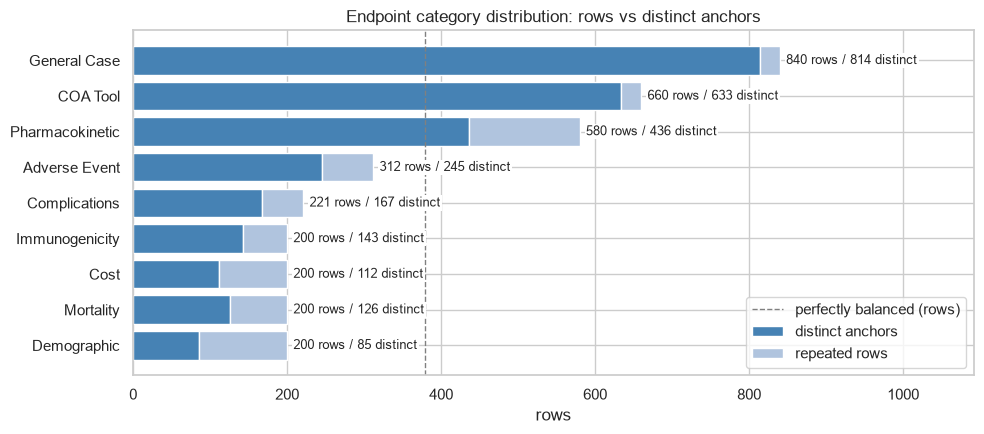

In [5]:
counts = df["case"].value_counts()
uniq_counts = df.drop_duplicates("anchor")["case"].value_counts().reindex(counts.index)
dist = pd.DataFrame({"rows": counts, "share_%": (counts / len(df) * 100).round(1),
                     "unique_anchors": uniq_counts})
print(dist.to_string())
print(f"\nImbalance ratio (largest / smallest class): {counts.max() / counts.min():.1f}x")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(dist.index, dist["unique_anchors"], color="steelblue", label="distinct anchors")
ax.barh(dist.index, dist["rows"] - dist["unique_anchors"], left=dist["unique_anchors"],
        color="lightsteelblue", label="repeated rows")
for i, (rows, uniq) in enumerate(zip(dist["rows"], dist["unique_anchors"])):
    ax.text(rows + 8, i, f"{rows} rows / {uniq} distinct", va="center", fontsize=9,
            bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax.axvline(len(df) / len(counts), ls="--", c="grey", lw=1, label="perfectly balanced (rows)")
ax.invert_yaxis()                                   # largest category at the top
ax.set(title="Endpoint category distribution: rows vs distinct anchors", xlabel="rows", ylabel="",
       xlim=(0, dist["rows"].max() * 1.3))
ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIG_DIR / "1a_class_distribution.png", dpi=120); plt.show()

**Observations - class balance**
- Three large classes (General Case 24.6%, COA Tool 19.3%, Pharmacokinetic 17.0%, `share_%` column above) account for 61% of the data; five classes sit at exactly 200 rows (5.9% each). Row-level imbalance is a moderate **4.2x** (840 / 200).
- Counted on **unique anchors**, the imbalance is much stronger: General Case has 814 distinct texts versus only **85 for Demographic** (**9.6x**, `unique_anchors` column above). The real information available for the small classes is smaller than row counts suggest.
- **Implications for Part 2:**
  - **Stratified splits**: every subset keeps the same proportion of each class.
  - **A class-weighted loss**: mistakes on small classes count more during training.
  - **Macro-F1** next to accuracy. For each category, **F1** scores how well the model both *finds* its items (**recall**: of the items that really are Demographic, how many did it find?) and *avoids false alarms* (**precision**: of the items it labelled Demographic, how many really are?), from 0 to 1. **Macro-F1** averages it over the 9 categories, so every category counts the same whatever its size, and a model that ignores a small category is penalised even when plain accuracy looks good.

    *Example:* on a test set of 90 General Case and 10 Demographic items, a model that always answers "General Case" gets **90% accuracy**, but its F1 is 0.95 for General Case and **0** for Demographic (it never finds one), so its **Macro-F1 is (0.95 + 0) / 2 ≈ 0.47**, exposing the problem.
- General Case is the largest class *and* a semantic catch-all, so it will likely attract errors from the others.

### 3. Text characteristics: length

**What:** measure each anchor's length in characters and words, compare across categories, and compare real vs synthetic texts (`is_synthetic`: real rows come from actual trial registrations, synthetic rows were artificially generated to add training examples; defined in detail in Section 5).

**Why:** short texts give the embedding model little context to work with (*"DM"* could mean diabetes mellitus or something else entirely). If some categories are systematically longer or shorter, length is also an indirect clue to the category.

**How to read the charts:**
- **Left, a box plot.** The box spans the middle 50% of the values, the line inside it is the median (the middle value), the whiskers show the typical range, and dots are unusually long or short texts.
- **Right, a histogram.** How often each length occurs, for real (blue) and synthetic (orange) texts. Each colour is normalised separately, so the two shapes can be compared even though synthetic texts are far more numerous.

          count  mean   std  min   25%   50%   75%    max
n_chars  3413.0  27.9  18.0  2.0  16.0  25.0  36.0  134.0
n_words  3413.0   3.6   2.4  1.0   2.0   3.0   4.0   23.0

Median words per category:
case
General Case       3.0
COA Tool           5.0
Pharmacokinetic    3.0
Adverse Event      3.0
Complications      3.0
Immunogenicity     3.0
Cost               3.0
Mortality          2.5
Demographic        2.0


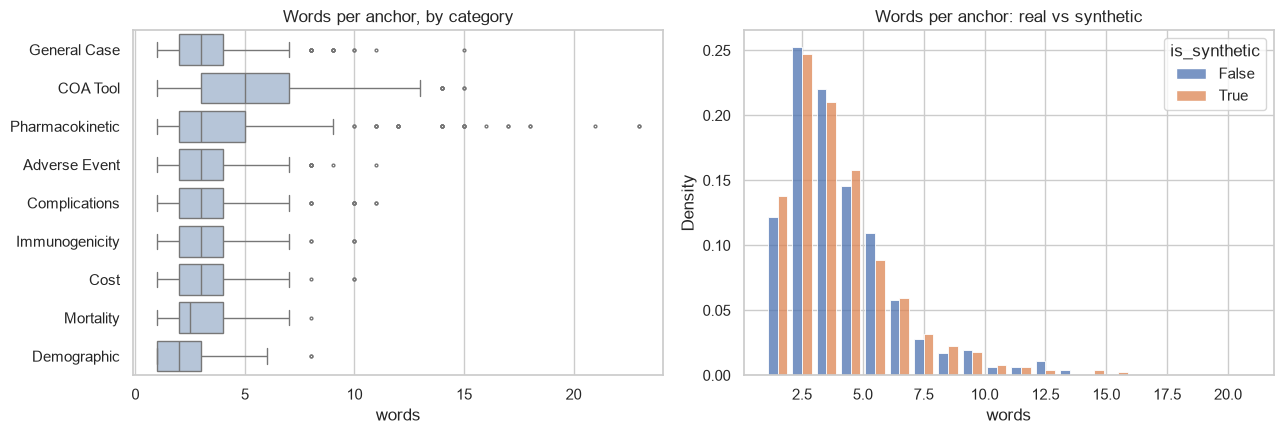

Shortest anchors: [['SG', 'Immunogenicity'], ['DM', 'Demographic'], ['DM', 'Demographic'], ['HZ', 'Adverse Event'], ['a*', 'Complications'], ['NE', 'Adverse Event'], ['NE', 'Adverse Event'], ['iC', 'Pharmacokinetic']]
One-word Demographic anchors (examples): ['Family', 'DM', 'Demographic', 'mothers', 'gender', 'Frailty', 'occupation', 'socioeconomic']


In [6]:
df["n_chars"] = df["anchor"].str.len()
df["n_words"] = df["anchor"].str.split().str.len()

print(df[["n_chars", "n_words"]].describe().round(1).T.to_string())
print("\nMedian words per category:")
print(df.groupby("case")["n_words"].median().reindex(CATEGORIES).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=df, y="case", x="n_words", order=CATEGORIES, ax=axes[0], color="lightsteelblue", fliersize=2)
axes[0].set(title="Words per anchor, by category", xlabel="words", ylabel="")
sns.histplot(data=df, x="n_words", hue="is_synthetic", bins=range(1, 22), multiple="dodge",
             stat="density", common_norm=False, shrink=0.8, ax=axes[1])
axes[1].set(title="Words per anchor: real vs synthetic", xlabel="words")
plt.tight_layout(); plt.savefig(FIG_DIR / "1a_text_length.png", dpi=120); plt.show()

print("Shortest anchors:", df.nsmallest(8, "n_chars")[["anchor", "case"]].values.tolist())
print("One-word Demographic anchors (examples):",
      df.loc[(df["case"] == "Demographic") & (df["n_words"] == 1), "anchor"].drop_duplicates().head(8).tolist())

**Observations - length**
- Endpoints are **very short**: median 3 words / 25 characters, 75% are 4 words or fewer (`50%` and `75%` columns of the summary table above). Classification depends on a handful of tokens, so a single ambiguous word can flip the category.
- **COA Tool** anchors are clearly longer (median 5 words: full instrument names like *"EORTC Quality of Life Questionnaire - Multiple Myeloma Module"*), **Demographic** the shortest (median 2; one-word examples above: *"occupation"*, *"gender"*, *"Frailty"*). Pharmacokinetic has the longest tail (detailed PK parameter definitions).
- Some anchors are bare 2-letter abbreviations (`SG`, `DM`, `HZ`, `NE`, "Shortest anchors" above), which are nearly impossible to classify without context.
- Real and synthetic anchors have **nearly identical length distributions**. Only 7% of synthetic rows (219 of 2,946) reuse an anchor that also appears in a real row (Section 5), so this is not just copying: the generated anchors mimic the form of real ones well.

**Why only words are plotted, not characters:** the two measures carry almost the same information here. The cell below shows that word and character counts are strongly correlated, and that the average word length is similar in every category, so a character chart would repeat the word chart on a different scale.

**What:** count **tokens** as a third measure, which is the one that matters for the model.

**Why:** the embedding model does not read words or characters but **tokens**. Its *tokenizer* splits text into pieces from a fixed vocabulary (30,522 entries, printed below): common words are one token, while rare words are split into sub-word fragments (marked `##`, meaning "continues the previous piece"). PubMedBERT, the base of the embedding model, learned its vocabulary from biomedical articles, so medical terms tend to be single tokens while unusual acronyms, drug names and typos get fragmented. A text split into many meaningless fragments is harder for the model to understand.

**How:** I load the tokenizer of the base model named in the README (`microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext`, downloaded from Hugging Face on the first run and cached afterwards; only the tokenizer, not the model; pinned to a fixed revision, like pinning a package version), tokenize every anchor, and compare categories with two measures:
- **tokens per word**: 1 means one token per word. It is only a rough measure, because punctuation also counts as tokens (*"28-day"* → `28`, `-`, `day`);
- **share of anchors with at least one fragmented word** (a word split into `##` pieces): the cleaner measure of how many texts contain words the model does not know as a whole. This one is plotted.

Correlation words vs characters: 0.93
Median characters per word, by category:
case
General Case       7.5
COA Tool           7.6
Pharmacokinetic    7.7
Adverse Event      7.9
Complications      9.0
Immunogenicity     8.0
Cost               7.0
Mortality          8.0
Demographic        7.1



Tokenizer vocabulary size: 30,522 entries

Examples of tokenization:
  'Cl/F'                                   -> ['cl', '/', 'f']
  'seroconversion rate'                    -> ['seroconversion', 'rate']
  'EORTC Quality of Life Questionnaire'    -> ['eo', '##rt', '##c', 'quality', 'of', 'life', 'questionnaire']
  'FKSI-DRS'                               -> ['fk', '##si', '-', 'drs']
  'dezamizumab'                            -> ['de', '##za', '##mi', '##zu', '##ma', '##b']
  'ethcnitiy'                              -> ['eth', '##cn', '##iti', '##y']

Tokens per anchor: median 4, max 34 (the model accepts up to 512, so nothing is cut off)
                 n_words  n_tokens  tokens_per_word  share_with_fragmented_word_%
case                                                                             
General Case         3.0       3.0             1.00                          21.0
COA Tool             5.0       6.0             1.33                          45.0
Pharmacokinetic      3.

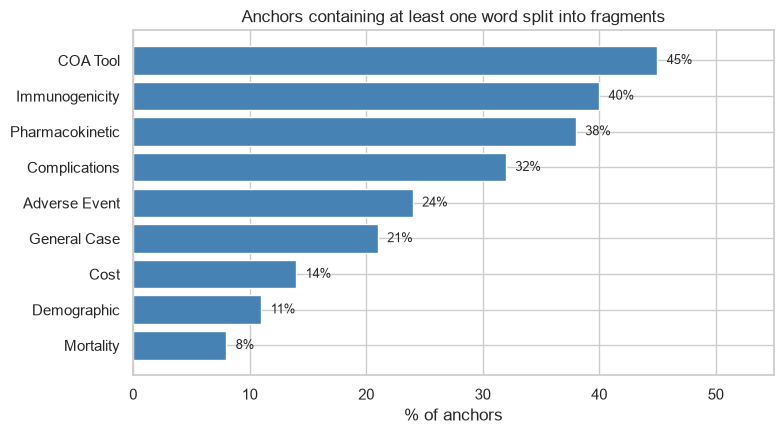

In [7]:
from transformers import AutoTokenizer

print(f"Correlation words vs characters: {df['n_words'].corr(df['n_chars']):.2f}")
print("Median characters per word, by category:")
print((df["n_chars"] / df["n_words"]).groupby(df["case"]).median().reindex(CATEGORIES).round(1).to_string())

tokenizer = AutoTokenizer.from_pretrained(
    "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext",
    revision="e1354b7a3a09615f6aba48dfad4b7a613eef7062",   # pinned: same vocabulary on every run
)
print(f"\nTokenizer vocabulary size: {len(tokenizer):,} entries")
df["n_tokens"] = df["anchor"].map(lambda s: len(tokenizer.tokenize(s)))
df["tokens_per_word"] = df["n_tokens"] / df["n_words"]

print("\nExamples of tokenization:")
for text in ["Cl/F", "seroconversion rate", "EORTC Quality of Life Questionnaire", "FKSI-DRS", "dezamizumab", "ethcnitiy"]:
    print(f"  {text!r:40} -> {tokenizer.tokenize(text)}")

print(f"\nTokens per anchor: median {df['n_tokens'].median():.0f}, max {df['n_tokens'].max()} "
      f"(the model accepts up to 512, so nothing is cut off)")
token_stats = (df.groupby("case")[["n_words", "n_tokens", "tokens_per_word"]].median()
                 .reindex(CATEGORIES).round(2))
token_stats["share_with_fragmented_word_%"] = (df.assign(frag=df["anchor"].map(
    lambda s: any(t.startswith("##") for t in tokenizer.tokenize(s)))).groupby("case")["frag"].mean() * 100).round(0)
print(token_stats.to_string())

frag = token_stats["share_with_fragmented_word_%"].sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(frag.index, frag.values, color="steelblue")
for i, v in enumerate(frag.values):
    ax.text(v + 0.8, i, f"{v:.0f}%", va="center", fontsize=9)
ax.set(title="Anchors containing at least one word split into fragments", xlabel="% of anchors", ylabel="",
       xlim=(0, 55))
plt.tight_layout(); plt.savefig(FIG_DIR / "1a_tokens_per_word.png", dpi=120); plt.show()

**Observations - tokens**
- Anchors are **short for the model too**: median 4 tokens, max 34, far below the model's 512-token limit, so no text is truncated.
- PubMedBERT's biomedical vocabulary covers clinical language well: *"seroconversion"* is a single token. Words are fragmented mainly when they are **acronyms, instrument names, drug names or typos**: *"EORTC"* → `eo ##rt ##c`, *"dezamizumab"* → 6 pieces, and the misspelling *"ethcnitiy"* (for *ethnicity*, which appears 5 times as a Demographic anchor, see "Most repeated anchors" in Section 1) → 4 meaningless pieces.
- Fragmentation differs clearly by category (chart above): **COA Tool (45%), Immunogenicity (40%) and Pharmacokinetic (38%)** contain the most fragmented words (instrument acronyms, antibody and drug names, PK abbreviations), while **Mortality (8%), Demographic (11%) and Cost (14%)** use everyday vocabulary.
- **Implication:** fragmentation alone does not make a category hard. COA Tool and PK are fragmented but very distinctive (Section 4); my hypothesis is that the fine-tuned model has learned what their recurring fragments mean, which Part 1C can check by measuring how well these categories cluster. Fragmentation matters most for **isolated acronyms and typos** (`SG`, `ethcnitiy`), where the pieces carry no meaning the model can use.

### 4. Text characteristics: style and terminology

**What:** for each category, measure the share of anchors that contain digits, acronyms (2+ consecutive capital letters, like `AUC`), parentheses, are entirely lowercase, or are in Title Case (most words capitalised, like a proper name).

**Why:** clinical text mixes abbreviations (`AUC`, `Cmax`, `ICER`), parenthesised acronyms and numbers. If a category has a recognisable *style*, that is a signal the embedding model can pick up, and it helps explain later which categories are easy.

**How:** each feature is a regular expression applied to every anchor, giving True/False per row; the mean per category is then the percentage of True. The heatmap shows these percentages: darker = more common.

Pharmacokinetic anchors with parentheses (examples): ['CL/F)', 'maximal and minimal concentration (Cmax, Cmin)', 'Accumulation index (AI)', "2',2'-Difluorodeoxyuridine (dFdU)", 'Minimum Inhibitory Concentration (MIC)']


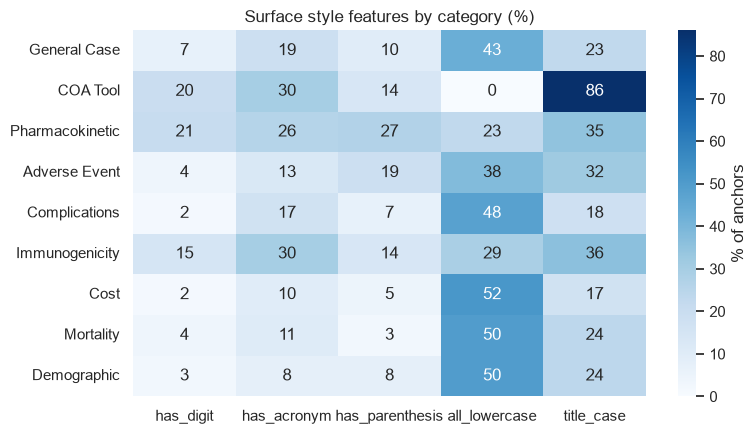

In [8]:
features = pd.DataFrame({
    "case": df["case"],
    "has_digit": df["anchor"].str.contains(r"\d"),
    "has_acronym": df["anchor"].str.contains(r"\b[A-Z]{2,}\b"),
    "has_parenthesis": df["anchor"].str.contains(r"[()]"),
    "all_lowercase": df["anchor"].str.match(r"^[^A-Z]*$"),
    "title_case": df["anchor"].apply(lambda s: sum(w[:1].isupper() for w in s.split()) / len(s.split()) > 0.6),
})
style = (features.groupby("case").mean() * 100).reindex(CATEGORIES).round(0)
print("Pharmacokinetic anchors with parentheses (examples):",
      df.loc[(df["case"] == "Pharmacokinetic") & features["has_parenthesis"], "anchor"]
        .drop_duplicates().sample(5, random_state=SEED).tolist())

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(style, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of anchors"}, ax=ax)
ax.set(title="Surface style features by category (%)", ylabel="", xlabel="")
plt.tight_layout(); plt.savefig(FIG_DIR / "1a_style_features.png", dpi=120); plt.show()

**What:** find the 10 most *distinctive* words of each category.

**Why:** the most *frequent* words are not informative (*"of"*, *"levels"* appear everywhere). The useful words are those frequent in one category **and rare in the others**: these are the keywords that make a category recognisable.

**How:** **TF-IDF** (term frequency × inverse document frequency) is a classic score that does exactly this. A word scores high if it appears often in a document (TF) but in few documents overall (IDF). Here I treat each category as one big "document", made of all its anchors concatenated, so the score highlights words specific to that category. Common English words (*"the"*, *"and"*) are excluded as *stop words*.

In [9]:
class_docs = df.groupby("case")["anchor"].apply(lambda s: " ".join(s)).reindex(CATEGORIES)
tfidf = TfidfVectorizer(lowercase=True, stop_words="english", token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z0-9\-]+\b")
X = tfidf.fit_transform(class_docs)                # one row per category, one column per word
vocab = np.array(tfidf.get_feature_names_out())
top_words = {c: ", ".join(vocab[np.argsort(-X[i].toarray()[0])[:10]]) for i, c in enumerate(CATEGORIES)}
pd.DataFrame.from_dict(top_words, orient="index", columns=["top distinctive words"])

,top distinctive words
General Case,"levels, time, protein, serum, frequency, plasma, physical, mass, blood, level"
COA Tool,"scale, questionnaire, quality, life, form, score, version, rating, assessmen..."
Pharmacokinetic,"plasma, concentration, curve, cmax, area, auc, concentration-time, time, con..."
Adverse Event,"adverse, events, treatment-emergent, aes, reactions, event, safety, effects,..."
Complications,"complications, postoperative, related, complication, injury, surgical, infec..."
Immunogenicity,"antibodies, antibody, titers, neutralizing, seroconversion, immunogenicity, ..."
Cost,"costs, cost, health, direct, economics, va, staff, program, indirect, economy"
Mortality,"mortality, death, all-cause, deaths, causes, cardiovascular, cardiac, in-hos..."
Demographic,"smoking, status, education, current, age, higher, habit, school, diagnosis, ..."


**What:** measure how many words each pair of categories has in common.

**Why:** if two categories use the same vocabulary, they will be hard to tell apart, and I expect the model to confuse them in Part 2.

**How:** for each category I build its set of distinct words (lowercased, without stop words). For each pair I compute the **Jaccard similarity** = (words in both) / (words in either). It goes from 0 (no shared words) to 1 (identical vocabularies). The diagonal (a category with itself) is hidden because it is always 1.

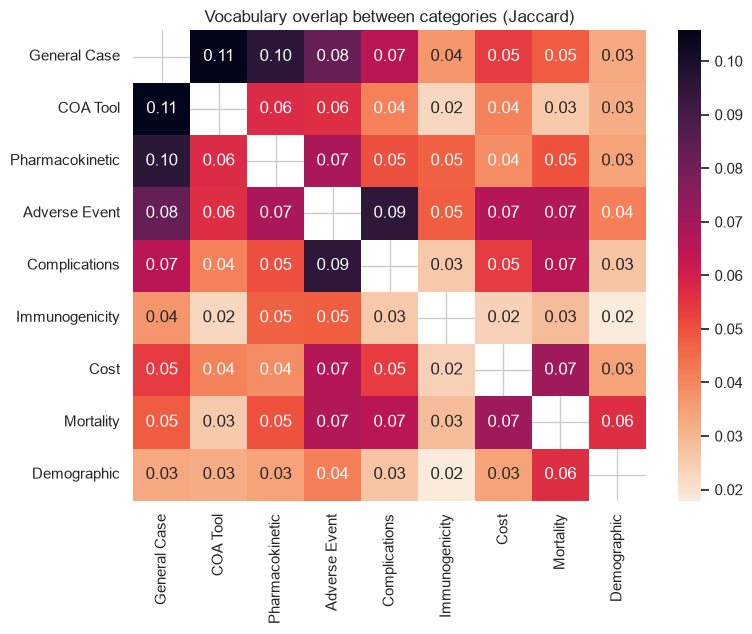

Vocabulary size per category: {'General Case': 1406, 'COA Tool': 1167, 'Pharmacokinetic': 572, 'Adverse Event': 327, 'Complications': 308, 'Immunogenicity': 247, 'Cost': 183, 'Mortality': 149, 'Demographic': 151}


In [10]:
tok = lambda s: {w for w in re.findall(r"[a-z][a-z0-9\-]+", s.lower()) if w not in ENGLISH_STOP_WORDS}
vocabs = {c: set().union(*df.loc[df["case"] == c, "anchor"].map(tok)) for c in CATEGORIES}
jac = pd.DataFrame([[len(vocabs[a] & vocabs[b]) / len(vocabs[a] | vocabs[b]) for b in CATEGORIES] for a in CATEGORIES],
                   index=CATEGORIES, columns=CATEGORIES)

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(jac, annot=True, fmt=".2f", cmap="rocket_r", mask=np.eye(len(CATEGORIES), dtype=bool), ax=ax)
ax.set(title="Vocabulary overlap between categories (Jaccard)")
plt.tight_layout(); plt.savefig(FIG_DIR / "1a_vocab_overlap.png", dpi=120); plt.show()
print("Vocabulary size per category:", {c: len(v) for c, v in vocabs.items()})

**Observations - terminology and vocabulary**
- Each category has **clear lexical anchors** (TF-IDF table): *scale/questionnaire/score* (COA Tool), *cmax/auc/concentration* (PK), *adverse/treatment-emergent/AEs* (AE), *antibodies/titers/seroconversion* (Immunogenicity), *mortality/death* (Mortality), *cost/economics* (Cost). Classes with such keywords should be easy.
- **Style is a strong cue for COA Tool** (style heatmap): 86% of its anchors are Title Case and none are fully lowercase (they are proper names of instruments). PK and Immunogenicity are rich in acronyms, digits and parentheses (e.g. *"Accumulation index (AI)"*, *"Minimum Inhibitory Concentration (MIC)"*, printed above the heatmap).
- **General Case has no distinctive vocabulary** (*levels, time, protein, serum*) and the largest vocabulary (1,406 words, printed under the Jaccard heatmap). It is a heterogeneous catch-all that shares the most words with COA Tool (0.11) and PK (0.10) in the Jaccard heatmap. The other notable pair is **Adverse Event / Complications (0.09)**: an endpoint such as a postoperative infection could reasonably be either. These are the confusions I expect in Part 2.
- Demographic and Immunogenicity have the most isolated vocabularies (lowest values in their rows of the heatmap).

### 5. Metadata flags

**What:** the dataset has three True/False columns that are not explained in the README. For each one I compute the share of True rows overall and per category.

**Why:** a flag could be useful information, a bias in the data (e.g. synthetic examples concentrated in one category), or a **leak**: a column that gives away the answer. A model trained with a leaking column looks great in testing and fails in real use, where that column does not exist.

**How:** as before, the mean of a True/False column is the share of True.

In [11]:
flags = ["is_coa_tool", "is_synthetic", "is_root_pair_similar"]
print("Overall share True:"); print((df[flags].mean() * 100).round(1).astype(str).add("%").to_string())
flag_pct = (df.groupby("case")[flags].mean() * 100).reindex(CATEGORIES).round(1)
flag_pct

Overall share True:
is_coa_tool             19.7%
is_synthetic            86.3%
is_root_pair_similar    35.0%


,is_coa_tool,is_synthetic,is_root_pair_similar
case,,,
General Case,1.5,84.9,28.2
COA Tool,100.0,86.7,38.3
Pharmacokinetic,0.0,88.1,45.0
Adverse Event,0.0,85.3,44.6
Complications,0.0,87.3,30.3
Immunogenicity,0.0,91.5,36.0
Cost,0.0,84.0,31.5
Mortality,0.0,85.5,27.5
Demographic,0.0,84.5,24.5


**What:** check whether `is_coa_tool` is just a copy of the label "COA Tool".

**Why:** the table above shows it is True for 100% of COA Tool rows. If it is (almost) never True elsewhere, it carries the answer itself and must not be used as an input to the classifier.

**How:** a **cross-tabulation** (`crosstab`) counts rows for each combination of two True/False values: (label is COA Tool?) × (flag is True?). Then I list the rows where the flag is True but the label is something else.

In [12]:
print(pd.crosstab(df["case"] == "COA Tool", df["is_coa_tool"],
                  rownames=["label == COA Tool"], colnames=["is_coa_tool"]))
print("\nRows flagged is_coa_tool but labelled General Case:")
print(df.loc[df["is_coa_tool"] & (df["case"] != "COA Tool"), "anchor"].tolist())

is_coa_tool        False  True 
label == COA Tool              
False               2740     13
True                   0    660

Rows flagged is_coa_tool but labelled General Case:
['Instrumented Stand and Walk test', 'Gait and Falls questionnaire', 'device usability survey', 'visual analogue scale', "Patient's Assessment of Arthritis", 'Radiographic criteria of response', 'Limitations in Daily Activities Scale', "Patient's Assessment of Arthritis", 'Socio-Behavioural Impact of COVID-19 on the General Population', 'total daily medications score', 'Non-Overt Disseminated Intravascular Coagulation', 'cumulative irritation score', 'scale of 6 classes']


**Observations - `is_coa_tool`**
- The flag is **True for all 660 COA Tool rows** and only 13 others (cross-table above; all General Case, e.g. *"visual analogue scale"*, *"Gait and Falls questionnaire"*). It is effectively a copy of the target, a **leakage risk**: it must *not* be used as a classifier input, since it would not be available for new, unlabeled endpoints.
- The 13 exceptions are interesting in their own right: several look like genuine assessment instruments labeled General Case, hinting at an inconsistent COA/General Case boundary in the labels.

**What does "synthetic" mean?** The README only says that the data "includes both real clinical trial endpoints and synthetically generated examples". **Real** rows come from actual trial registrations; **synthetic** rows were artificially generated (the README does not say how; typically by a language model or templates) to create more training examples for the embedding model.

The flag describes the **row**, i.e. the whole triplet, not necessarily the anchor text. To check what is actually generated, I count how many anchors appear only in real rows, only in synthetic rows, or in both, and show examples of the last group.

In [13]:
real_anchors = set(df.loc[~df["is_synthetic"], "anchor"])
synthetic_anchors = set(df.loc[df["is_synthetic"], "anchor"])
synthetic_rows = df[df["is_synthetic"]]
print(f"Distinct anchors only in real rows:      {len(real_anchors - synthetic_anchors)}")
print(f"Distinct anchors only in synthetic rows: {len(synthetic_anchors - real_anchors)}")
print(f"Distinct anchors in both:                {len(real_anchors & synthetic_anchors)}")
print("  examples only in synthetic rows:",
      pd.Series(sorted(synthetic_anchors - real_anchors)).sample(5, random_state=SEED).tolist())
print(f"Synthetic rows whose anchor also appears in a real row: "
      f"{synthetic_rows['anchor'].isin(real_anchors).sum()} of {len(synthetic_rows)}")
print("\nExamples of anchors in both real and synthetic rows:")
both = df[df["anchor"].isin(real_anchors & synthetic_anchors)]
print(both[both["anchor"].isin(["28-day mortality", "11C]-raclopride"])]
      .sort_values(["anchor", "is_synthetic"])[["anchor", "positive", "negative", "is_synthetic"]].to_string(index=False))

Distinct anchors only in real rows:      311
Distinct anchors only in synthetic rows: 2298
Distinct anchors in both:                152
  examples only in synthetic rows: ['Progression to Diabetes', 'β‐cell function and mass', 'BOI‐90AUC', 'SS-QOL', 'CYP2C19 genotype']
Synthetic rows whose anchor also appears in a real row: 219 of 2946

Examples of anchors in both real and synthetic rows:
          anchor              positive                    negative  is_synthetic
 11C]-raclopride        11C-raclopride blood glucose concentration         False
 11C]-raclopride        raclopride AUC      white blood cell count          True
28-day mortality 30-day mortality rate      target prostate volume         False
28-day mortality  28-day survival rate       gland size evaluation          True


**Observations - what is synthetic**
- **Most synthetic rows have generated anchors**: 2,298 distinct anchors appear only in synthetic rows (output above, e.g. *"Progression to Diabetes"*, *"CYP2C19 genotype"*).
- **A minority reuse a real anchor** with newly generated positives/negatives: 152 anchors appear in both kinds of rows, in 219 synthetic rows (output above). For example *"28-day mortality"* is paired with *"30-day mortality rate"* in a real row and with *"28-day survival rate"* in a synthetic one, and the truncated fragment *"11C]-raclopride"*, clearly extracted from a real registration, also appears in a synthetic row.
- So "synthetic" means "this triplet was generated", which *usually* but not always includes the anchor.

**What:** print 5 random anchors for each category, separately for real and synthetic rows (`is_synthetic`).

**Why:** statistics cannot tell me whether a *label is wrong*; only reading examples can. Comparing real and synthetic rows also shows whether the two sources differ in quality.

**How:** `sample(5, random_state=SEED)` picks 5 random rows; the seed makes it pick the same 5 on every run, so the examples quoted below stay valid.

In [14]:
rows = []
for c in CATEGORIES:
    for synth in (False, True):
        sub = df.loc[(df["case"] == c) & (df["is_synthetic"] == synth), "anchor"]
        rows.append({"case": c, "synthetic": synth, "examples": " | ".join(sub.sample(5, random_state=SEED))})
pd.DataFrame(rows).set_index(["case", "synthetic"])

examples
case            synthetic                                                                                 
General Case    False      Oxygen saturation (%) | conjunctival hyperemia | Serum homocystein concentra...
                True       adipose tissue capacity for fat uptake from chylomicron | headache diary | A...
COA Tool        False      Glasgow outcome score | FKSI-DRS | Glaucoma Computer Adaptive Test - Ocular ...
                True       GDS | BVAS | EORTC Quality of Life Questionnaire - Multiple Myeloma Module |...
Pharmacokinetic False      6-Beta-naltrexol | Model-Based Oral Clearance (CL/F) | Maximum serum concent...
                True       blood hydroxyeycosatetraenoic acid concentration | Plasma Concentrations of ...
Adverse Event   False      Occurrence of esophagitis grade 3 or higher | treatment-emergent AEs | Adver...
                True       serious and non-serious events | Premature Permanent Discontinuation of IP D...
Complications   False      re-ruptures | periprocedural complications | Pulmonary Complications | sever...
                True       severity of postoperative liver failure | hematoma, or other complication re...
Immunogenicity  False      immunotherapy-induced grass pollen-specific IgG4 levels | ADA incidence | fu...
                True       Anti-Paired Basic Amino Acid Cleaving Enzyme (PACE) Furin | Anti-Therapeutic...
Cost            False      order of | Healthcare cost | Health economy related to | costs throughout pr...
                True       staff time savings | SAP | use or cost of resources | costs throughout progr...
Mortality       False      All-cause death or | AVR | twist | adjudicated non-sudden cardiac death | ad...
                True       cerebrospinal fluid tau to amyloid beta | Mortality during hospitalization |...
Demographic     False      Relationships and Social Ties" | Current smoker | Genotype of SCD/SCD-plus |...
                True                male partners | unemployment | Smoking Status | U(K)V | pubertal state

**What:** look up a few anchors whose label looks wrong, found while browsing the data, and check whether they occur in real rows, synthetic rows or both.

**Why:** the random sample above shows only 5 examples per group; these lookups make the label-noise examples quoted below verifiable.

In [15]:
suspicious = ["AVR", "twist", "eyetracking device", "improved", "order of", "present pain intensity",
              "respiratory functions"]
(df[df["anchor"].isin(suspicious)]
   .groupby(["anchor", "case"])["is_synthetic"]
   .agg(real_rows=lambda s: (~s).sum(), synthetic_rows="sum")
   .reset_index())

,anchor,case,real_rows,synthetic_rows
0,AVR,Mortality,1,0
1,eyetracking device,Mortality,1,0
2,improved,Mortality,1,3
3,order of,Cost,1,3
4,present pain intensity,Cost,1,1
5,respiratory functions,Immunogenicity,1,2
6,twist,Mortality,1,2


**Observations - real vs synthetic (`is_synthetic`)**
- **2,946 of 3,413 rows (86.3%) are synthetic** ("Overall share True" at the start of Section 5), and the share is similar in every category, from 84.0% (Cost) to 91.5% (Immunogenicity) (`is_synthetic` column of the table below it), so the synthetic share does not bias any single class.
- Manual inspection shows **label noise originating in real anchors** (lookup table above): Mortality contains *"AVR"*, *"twist"*, *"eyetracking device"*, *"improved"*; Cost contains *"order of"* and *"present pain intensity"*; Immunogenicity contains *"respiratory functions"*. All 7 appear in a real row, and **5 of them were also copied into synthetic rows** that reuse the anchor, so the noise propagates. Several real anchors are **truncated fragments** (*"All-cause death or"*, *"Health economy related to"*, random sample above), suggesting automated extraction from trial registries. Synthetic rows with generated anchors look generally cleaner, though not perfect (*"cerebrospinal fluid tau to amyloid beta"* labeled Mortality).
- **Implication:** a ceiling on achievable accuracy, and errors on real rows may be the *label's* fault rather than the model's. I will report test performance split by real vs synthetic in Part 2.

**What:** `is_root_pair_similar` is undocumented, so I try to infer its meaning by printing 6 random triplets where it is True and 6 where it is False.

**Why:** its name suggests it describes the relationship *within* the triplet (anchor, positive, negative). Seeing examples side by side is the quickest way to spot the difference.

In [16]:
for flag in (True, False):
    print(f"--- is_root_pair_similar = {flag}")
    print(df.loc[df["is_root_pair_similar"] == flag, ["anchor", "positive", "negative", "case"]]
            .sample(6, random_state=SEED).to_string(index=False), "\n")

--- is_root_pair_similar = True
                                         anchor                         positive                           negative         case
                                    WOMAC LK 3.             WOMAC Likert Scale 3                       Weekly WOMAC     COA Tool
                                   CV mortality death from cardiovascular causes        treatment-related mortality    Mortality
     Dundee Ready Education Environment Measure                            DREEM Self-reported Foot and Ankle Score     COA Tool
Glover-Nilsson Smoking Behavioral Questionnaire              Glover-Nilsson Test     Smoking Behavior Questionnaire     COA Tool
                    Affective Dimension of Pain          emotional pain response        mechanical pain sensitivity General Case
        costs throughout program implementation       intervention cost analysis             out-of-pocket expenses         Cost 

--- is_root_pair_similar = False
                              

**Observations - `is_root_pair_similar`**
- The flag is not documented. From the examples, when it is True the **negative is semantically close to the anchor** (*"CV mortality"* vs negative *"treatment-related mortality"*; *"WOMAC LK 3."* vs *"Weekly WOMAC"*), whereas when False the negative is unrelated (*"serum digoxin concentrations"* vs *"blood pressure measurements"*). My interpretation: **True marks a hard negative**, used to teach fine distinctions.
- Hard negatives are most common in PK (45.0%) and Adverse Event (44.6%) (`is_root_pair_similar` column of the flag table at the start of Section 5), the categories where fine-grained distinctions matter most (different PK parameters, different AE types). It is irrelevant as a classifier input, but relevant when evaluating the embedding model on its own triplets (one of the bonus options), where hard-negative triplets should be the hardest to get right.

### Part 1A Summary: key insights

1. **Duplicated anchors (19% of rows) concentrated in small classes** (Section 1). Only 2,761 of 3,413 anchors are unique; Demographic has just 85 distinct texts for 200 rows. This means the API only needs to embed unique texts (Part 1B), and **Part 2 must split by unique text** to avoid train/test leakage that would inflate scores for exactly the classes that are hardest to learn.
2. **Moderate row imbalance (4.2x), strong effective imbalance (9.6x on unique texts)** (Section 2). I will use stratified splits, class-weighted loss, and report macro-F1 alongside accuracy.
3. **Very short inputs** (Section 3). The median endpoint is 3 words (4 tokens), and some are bare 2-letter acronyms (`SG`, `DM`). The classifier relies entirely on how well the embedding model encodes a few tokens, with little context to resolve ambiguity.
4. **Most classes have strong lexical signatures** (Section 4). COA Tool (Title Case instrument names, *scale/questionnaire*), PK (*AUC, Cmax, concentration*), Immunogenicity, Mortality and Cost are keyword-driven and should be easy. **General Case** is a heterogeneous catch-all with no distinctive vocabulary and the highest overlap with COA Tool and PK: I expect it to be the main error sink, alongside the semantically adjacent **Adverse Event / Complications** pair.
5. **`is_coa_tool` is a near-perfect proxy for the COA Tool label** (Section 5). Using it as a feature would be target leakage; it is excluded from modeling.
6. **Label noise exists** (Sections 1 and 5): 6 anchors with conflicting labels, mislabeled examples (*"eyetracking device"* as Mortality) that originate in real rows and are partly copied into synthetic ones, and truncated fragments. This caps achievable accuracy; some "errors" will reflect the labels, not the model.
7. **The dataset is 86% synthetic, evenly across classes** (Sections 3 and 5), with real and synthetic text sharing the same length profile. A test set drawn from it mostly measures performance on synthetic-style data, so performance on real-world endpoints may be lower than reported.